In [391]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn


%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
from src.plots import *
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography.algorithms import FeedbackHologram
%load_ext autoreload
%autoreload 2
# mpl.rc('image', cmap='Blues')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [392]:
from slmsuite.hardware.cameraslms import FourierSLM

try:
    # Try to load physical hardware.
    from slmsuite.hardware.slms.santec import Santec
    from slmsuite.hardware.cameras.alliedvision import AlliedVision

    # Load the hardware.
    slm = Santec(slm_number=1, display_number=2, wav_um=.633, settle_time_s=.5); print()
    cam = AlliedVision(serial="02C5V", verbose=True, fliplr=True)

    # Load the composite CameraSLM.
    fs = FourierSLM(cam, slm)
    fs.read_calibration("wavefront_superpixel")
    fs.wavefront_calibration_superpixel_process(r2_threshold=.5, plot=True);
except Exception as e:
    print(f"Loading physical hardware failed; loading virtual hardware. Error:\n{str(e)}")
    # Fallback to virtual hardware.
    from slmsuite.hardware.slms.simulated import SimulatedSLM
    from slmsuite.hardware.cameras.simulated import SimulatedCamera

    # Make the SLM and camera.
    slm = SimulatedSLM((1600, 1200), pitch_um=(8,8))
    slm.set_source_analytic(sim=True)               # Program the virtual source.
    slm.set_source_analytic()                       # Don't bother with wavefront calibration, instead just set it to the same source.

    cam = SimulatedCamera(slm, (1440, 1100), pitch_um=(4,4), gain=200)

    # Tie the camera and SLM together with an analytic calibration.
    fs = FourierSLM(cam, slm)
    M, b = fs.fourier_calibration_build(
        f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
        theta=5 * np.pi / 180,
    )
    cam.set_affine(M, b)
    fs.fourier_calibrate_analytic(M, b)

Loading physical hardware failed; loading virtual hardware. Error:
Santec DLLs not installed. Install these to use Santec SLMs.  Dynamically linked libraries from Santec (usually provided via USB) must be present in the runtime directory:
  - SLMFunc.dll
  - FTD3XX.dll
  Check that these files are present and are error-free.


In [393]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [394]:
fs = slm_initialise(force=True,verbose=True)

Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
Looking for cameras... success
ThorCam sn '12975' initializing... success


smooth:   0%|          | 0/16 [00:00<?, ?it/s]

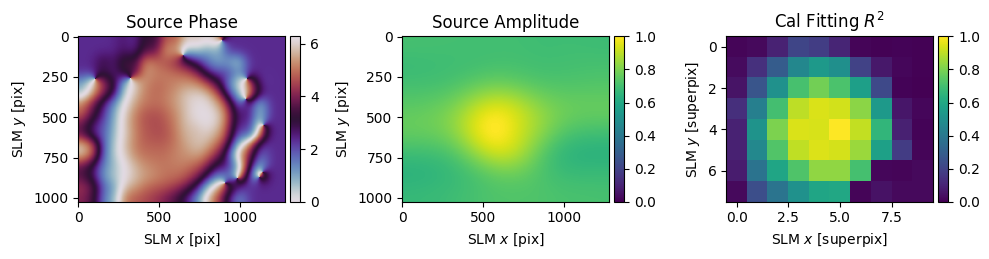

array([[3, 1, 1, ..., 2, 2, 2],
       [1, 2, 1, ..., 2, 2, 1],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [3, 2, 2, ..., 2, 2, 1],
       [2, 2, 3, ..., 2, 2, 2],
       [2, 3, 1, ..., 2, 2, 2]], dtype=uint16)

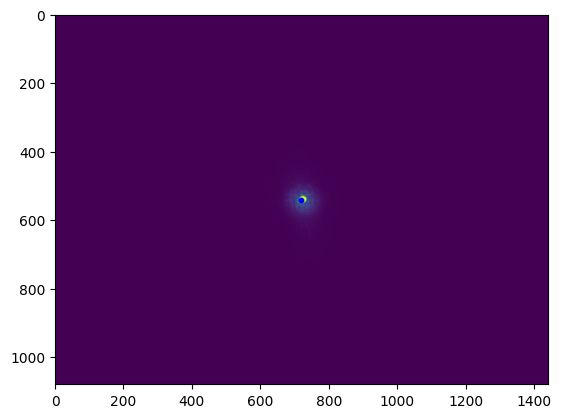

In [395]:
calibrate(fs,vendor = True,refresh = False)
sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

In [396]:
target_shape = fs.cam.shape
j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')

centrex = 1180
centrey = 230
n_spots = 5
r = 50
n = 4
rad = 100
bb_locations = np.array([[centrex+(i-2)*rad ,centrey + (j-1)*rad] for i in range(n) for j in range(n)]).T
spot_locations = np.array([[centrex+(i-2)*rad + 50,centrey + (j-1)*rad + 50] for i in range(n) for j in range(n)]).T
target = np.zeros(target_shape)
for spot_location in spot_locations.T:
    xc, yc = spot_location
    target = target + g(i,j,52.23977353,5.47581198,xc, yc)
for bb_location in bb_locations.T:
    xc, yc = bb_location
    target = target + bb(i,j,1.30590871e+04,1.30660485e+04,8.56061191e+00,8.54272142e+00,xc,yc)

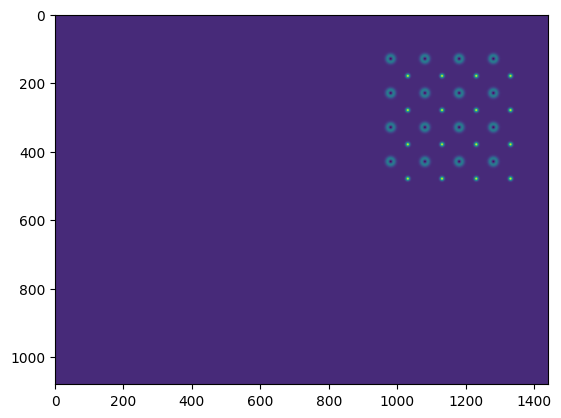

In [6]:
plt.imshow(target)

In [9]:
from numpy import dtype

class SLMModel(nn.Module):
    def __init__(self, fs,citl = False,phase = None):
        super().__init__()
        self.fs = fs
        self.slm_shape = fs.slm.shape
        if phase is None:
            self.phi_nf = nn.Parameter(torch.zeros(self.slm_shape))  # Learnable phase
        else:
            self.phi_nf = nn.Parameter(torch.tensor(phase))
        self.A_nf = torch.tensor(self.fs.slm.source['amplitude']/FeedbackHologram._norm(self.fs.slm.source['amplitude']),dtype=torch.float32)  # Fixed amplitude
        self.citl = citl  # Closed-loop mode (use camera)
        self.fholo = FeedbackHologram(shape = fs.slm.shape,cameraslm = fs)

    def forward(self):
        # Construct field in near field
        F_nf = self.A_nf * torch.exp(1j * self.phi_nf)

        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(F_nf),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        if self.citl:
            # Write phase to SLM and get real camera image
            self.fs.slm.write(self.phi_nf.detach().cpu().numpy(),settle = True)
            A_cam = self.fs.cam.get_image()
            A_cam_ff = torch.tensor(self.fholo.ijcam_to_knmslm(A_cam)/FeedbackHologram._norm(self.fholo.ijcam_to_knmslm(A_cam)),dtype=torch.float32)
            A_cam_ff[torch.isnan(A_cam_ff)] = 0
            # Use A_cam_ff in loss, but keep gradients from A_ff
            # Equivalent to: A_out = A_cam_ff - (A_cam_ff - A_ff).detach()
            A_out = A_ff + (A_cam_ff - A_ff).detach()
        else:
            A_out = A_ff

        # Return simulated/measured amplitude for loss
        return A_out

In [232]:
# no camera 
import torch.optim.lbfgs


A_target = np.zeros(fs.cam.shape)
A_target[400:420,400:420] = 1
A_target = target
model = SLMModel(fs,citl=True)
# A_target_norm = torch.tensor(A_target/FeedbackHologram._norm(A_target),dtype=torch.float32)
# # A_target_norm[torch.isnan(A_target_norm)] = 0

A_target_norm = torch.tensor(model.fholo.ijcam_to_knmslm(A_target)/FeedbackHologram._norm(model.fholo.ijcam_to_knmslm(A_target)),dtype=torch.float32)
A_target_norm[torch.isnan(A_target_norm)] = 0

optimizer = torch.optim.Adam(model.parameters(), lr=1)
A_outs = []
losses = []
phases = []
num_steps = 120
for step in range(num_steps):
    optimizer.zero_grad()
    A_out = model()
    loss = torch.nn.functional.mse_loss(A_out*A_out, A_target_norm*A_target_norm)*fs.slm.shape[0]*fs.slm.shape[1]*100
    loss.backward()
    optimizer.step()
    losses.append(loss.detach())
    if step%10 ==0:
        A_outs.append(A_out.detach().cpu().numpy())
        phases.append(model.phi_nf.detach().cpu().numpy())
        print(f"Step {step+1}/{num_steps}, Loss: {loss.item()*1}")

Step 1/120, Loss: 4.962922096252441
Step 11/120, Loss: 4.3484578132629395
Step 21/120, Loss: 1.2881988286972046
Step 31/120, Loss: 1.0845671892166138
Step 41/120, Loss: 1.1049604415893555
Step 51/120, Loss: 1.0438295602798462
Step 61/120, Loss: 0.9523050785064697
Step 71/120, Loss: 0.8871181607246399
Step 81/120, Loss: 0.8440550565719604
Step 91/120, Loss: 0.8181731104850769
Step 101/120, Loss: 0.9900470972061157
Step 111/120, Loss: 1.72266685962677


In [10]:
phi_off = model.phi_nf.detach().cpu().numpy()
fs.slm.write(phi_off,settle=True)

NameError: name 'model' is not defined

In [227]:
A_cam = fs.cam.get_image()

In [217]:
plt.imshow(A_outs[9999][500:650,600:750])

IndexError: list index out of range

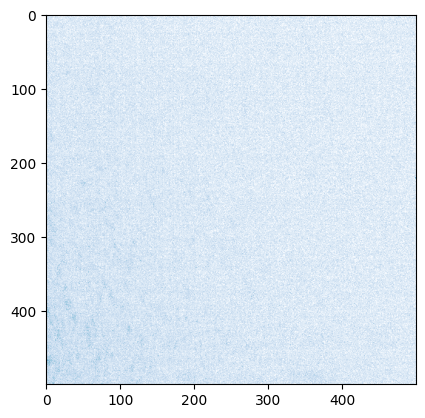

In [228]:
plt.imshow(A_cam[100:600,900:1400])

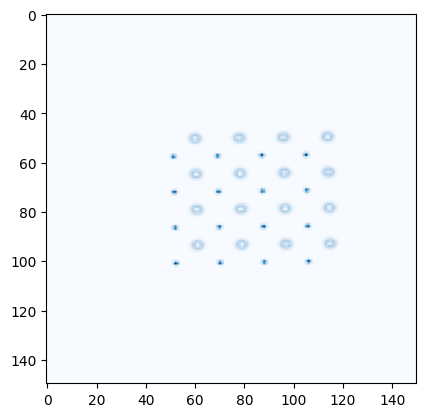

In [158]:
plt.imshow(A_target_norm[500:650,600:750])

array([[2, 2, 1, ..., 1, 1, 2],
       [2, 2, 1, ..., 2, 1, 1],
       [2, 1, 2, ..., 2, 1, 2],
       ...,
       [2, 2, 2, ..., 2, 3, 2],
       [3, 2, 4, ..., 3, 2, 2],
       [2, 3, 1, ..., 3, 2, 3]], dtype=uint16)

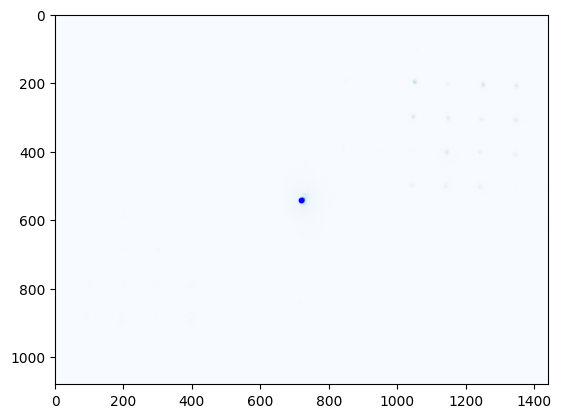

In [ ]:
plot_cam(fs,centre=True, save=True)

In [ ]:
(A_target_norm*A_target_norm).sum(),(A_out*A_out).sum()

(tensor(1.0000), tensor(1.0000, grad_fn=<SumBackward0>))

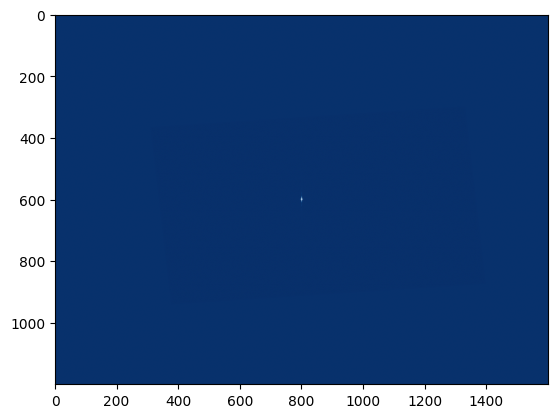

In [ ]:
plt.imshow( A_target_norm - A_out.detach() )

In [ ]:
A_out.detach() - A_target_norm 

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [621]:
from lmfit.models import Gaussian2dModel
from lmfit.lineshapes import gaussian2d
def gs_algo(fs,iters, A_target):
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(fs.slm.source['amplitude']/FeedbackHologram._norm(fs.slm.source['amplitude']),dtype=torch.float32)
    A_t = torch.tensor(A_target/FeedbackHologram._norm(A_target),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff

def create_target(spot_vectors,fs,spot_intensities=None):
    w = toolbox.convert_radius(fs.slm.get_spot_radius_kxy(),from_units='kxy',to_units='knm',hardware=fs)
    target = np.zeros(fs.slm.shape)
    target_shape = target.shape
    j,i = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')
    for spot_location in spot_vectors:
        xc, yc = toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_location),from_units='kxy',to_units='knm',hardware = fs)
        target = target + g(i,j,1,w,xc, yc)
    return target



def create_target_spots(spot_vectors,fs,spot_weights=None):
    target = np.zeros(fs.slm.shape)
    target_shape = target.shape
    if spot_weights is None:
        spot_weights = np.ones(spot_vectors.shape[0])
    for i in range(spot_vectors.shape[0]):
        spot_location = spot_vectors[i]
        xc, yc = toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_location),from_units='kxy',to_units='knm',hardware = fs)
        target[int(yc),int(xc)] = spot_weights[i]
    return target/FeedbackHologram._norm(target)

def create_target_spotsw(spot_vectors,fs,spot_weights=None):
    target = np.zeros(fs.slm.shape)
    target_shape = target.shape
    if spot_weights is None:
        spot_weights = np.zeros((spot_vectors.shape[0],5))
        spot_weights[:,0] = 1
    for i in range(spot_vectors.shape[0]):
        print(i)
        spot_location = spot_vectors[i]
        xc, yc = toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_location),from_units='kxy',to_units='knm',hardware = fs)
        X,Y = (toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_weights[i,1:3]),from_units='kxy',to_units='knm',hardware = fs)
        -toolbox.convert_vector(fs.ijcam_to_kxyslm([0,0]),from_units='kxy',to_units='knm',hardware = fs))
        ym,xm = np.meshgrid(np.arange(target.shape[1]),np.arange(target.shape[0]))
        print(X,Y,xc,yc,spot_weights[i,0])
        target = target + gaussian2d(xm, ym, amplitude=spot_weights[i,0], centerx=int(xc[0]), centery=int(yc[0]), sigmax=X[0], sigmay=Y[0])
    return target/FeedbackHologram._norm(target)

def get_fit_params_lm(target):
    xdata = np.array([[i,j] for i in range(target.shape[0]) for j in range(target.shape[1])]).T
    model = Gaussian2dModel()
    params = model.guess(target.ravel(),xdata[0].ravel(),xdata[1].ravel())
    result = model.fit(target.ravel(),params,x = xdata[0].ravel(),y = xdata[1].ravel(),max_nfev = 10000)
    return [result.params['height'].value,result.params['sigmax'].value,result.params['sigmay'].value,result.params['centerx'].value,result.params['centery'].value]

def create_target_spots_i(spot_vectors,fs,phase,spot_weights):
    params = []
    out = plot_cam(fs=fs,phase = phase,plot = False,sleep=3)
    for spot_location in spot_vectors:
        # plt.figure()
        # plt.imshow(out[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50])
        # params.append(get_fit_params(out[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50],trap = 'g',plot=False,verbose=False))
        params.append(get_fit_params_lm(out[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50]))
    spot_intensities = np.array(params).T[0]
    spi_mean = np.mean(spot_intensities)
    print(spot_intensities)
    print(f"variation is {np.std(spot_intensities)/np.mean(spot_intensities) * 100}")
    spot_weights[:,0] = spot_weights[:,0]*np.sqrt(spi_mean/spot_intensities)
    return create_target_spots(spot_vectors,fs,spot_weights.T[0]),spot_weights


def create_target_spots_w(spot_vectors,fs,phase,spot_weights):
    params = []
    out = plot_cam(fs=fs,phase = phase,plot = False,sleep=3)
    plt.figure()
    plt.imshow(out)
    for spot_location in spot_vectors:
        params.append(get_fit_params_lm(out[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50]))
    spot_w = np.array(params)
    spot_mean = np.mean(spot_w,axis=0)
    spot_std = np.std(spot_w,axis=0)
    print(f"variation is {np.std(spot_w,axis = 0)/np.mean(spot_w,axis = 0) * 100}")
    spot_weights[:,0] = spot_weights[:,0]*np.sqrt(spot_mean[0]/spot_w.T[0])
    spot_weights[:,1] = spot_weights[:,1] - spot_w[:,1] + spot_mean[1]
    spot_weights[:,2] = spot_weights[:,2] - spot_w[:,2] + spot_mean[2]
    print(spot_weights)
    return create_target_spotsw(spot_vectors,fs,spot_weights),spot_weights

def update_weights(fs,phase,spot_vectors,spot_weights,only_amp = False):
    out = plot_cam(fs=fs,phase = phase,plot = False,sleep=3)
    # plt.figure()
    # plt.imshow(out)
    params = []
    for spot_location in spot_vectors:
        params.append(get_fit_params_lm(out[spot_location[1]-50:spot_location[1]+50,spot_location[0]-50:spot_location[0]+50]))
    spot_w = np.array(params)
    # print(spot_w[:,1])
    spot_mean = np.mean(spot_w,axis=0)
    spot_std = np.std(spot_w,axis=0)
    print(f"variation is {np.std(spot_w,axis = 0)/np.mean(spot_w,axis = 0) * 100}")
    spot_weights[:,0] = spot_weights[:,0]*np.sqrt(spot_mean[0]/spot_w.T[0])
    if only_amp == False:
        spot_weights[:,1] = spot_weights[:,1] + (- spot_w[:,1] + spot_mean[1])/800
        spot_weights[:,2] = spot_weights[:,2] + (- spot_w[:,2] + spot_mean[2])/800
        spot_weights[:,3] = spot_weights[:,3] + (- spot_w[:,3] + spot_mean[3])/-1
        spot_weights[:,4] = spot_weights[:,4] + (- spot_w[:,4] + spot_mean[4])/2
    # print(spot_weights)
    return spot_weights

def gs_algo_spots(fs,iters, spot_vectors):
    A_t = torch.tensor(create_target(spot_vectors.T,fs))
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(fs.slm.source['amplitude']/FeedbackHologram._norm(fs.slm.source['amplitude']),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff,phi_nf

def wgs_algo_spots(fs,iters, spot_vectors):
    A_t = torch.tensor(create_target_spots(spot_vectors.T,fs))
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(np.ones(fs.slm.shape)/FeedbackHologram._norm(np.ones(fs.slm.shape)),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)
        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff,phi_nf


def wgs_algo_spots_i(fs,iters, spot_vectors):
    A_t = torch.tensor(create_target_spots(spot_vectors.T,fs))
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(np.ones(fs.slm.shape)/FeedbackHologram._norm(np.ones(fs.slm.shape)),dtype=torch.float32)
    spot_weights = np.zeros((spot_vectors.T.shape[0],5))
    spot_weights[:,0] = 1
    phis = []
    for iter in range(100):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)
        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    for iter in range(10):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        # phi_ff = torch.angle(F_ff)
        # Propagate back to near field
        A_t,spot_weights = create_target_spots_i(spot_vectors.T,fs = fs,phase = phi_nf.detach().cpu().numpy(),spot_weights = spot_weights)
        A_t = torch.tensor(A_t)
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
        phis.append(phi_nf.detach().cpu().numpy())
    
    # for iter in range(10):
    #     # Propagate to far field
    #     F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
    #     A_ff = torch.abs(F_ff)
    #     # phi_ff = torch.angle(F_ff)
    #     # Propagate back to near field
    #     A_t,spot_weights = create_target_spots_w(spot_vectors.T,fs = fs,phase = phi_nf.detach().cpu().numpy(),spot_weights = spot_weights)
    #     A_t = torch.tensor(A_t)
    #     F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
    #     A_nf = torch.abs(F_nf)
    #     phi_nf = torch.angle(F_nf)
    #     print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    #     phis.append(phi_nf.detach().cpu().numpy())
    return A_ff,phi_nf,phis

In [573]:
# A_ff,phi_nf,phis = wgs_algo_spots_i(fs = fs, spot_vectors=bb_locations,iters = 30)

In [626]:
spot_vectors=spot_locations
A_t = torch.tensor(create_target_spots(spot_vectors.T,fs))
phi_nf = torch.zeros(fs.slm.shape)
A_input = torch.tensor(np.ones(fs.slm.shape)/FeedbackHologram._norm(np.ones(fs.slm.shape)),dtype=torch.float32)
spot_weights = np.zeros((spot_vectors.T.shape[0],5))
spot_weights[:,0] = 1
F_ff = None
for iter in range(100):
    # Propagate to far field
    F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
    A_ff = torch.abs(F_ff)
    phi_ff = torch.angle(F_ff)
    # Propagate back to near field
    F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
    A_nf = torch.abs(F_nf)
    phi_nf = torch.angle(F_nf)
    print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
# for iter in range(10):
#     # Propagate to far field
#     F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
#     A_ff = torch.abs(F_ff)
#     # phi_ff = torch.angle(F_ff)
#     # Propagate back to near field
#     A_t,spot_weights = create_target_spots_i(spot_vectors.T,fs = fs,phase = phi_nf.detach().cpu().numpy(),spot_weights = spot_weights)
#     A_t = torch.tensor(A_t)
#     F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
#     A_nf = torch.abs(F_nf)
#     phi_nf = torch.angle(F_nf)
#     print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
#     phis.append(phi_nf.detach().cpu().numpy())
phi_nf_copy = phi_nf.clone()
spot_weights_copy = spot_weights.copy()

1.0625
0.01347842284931846
0.01347842284931846
0.013478422849318458
0.013478422849318456
0.013478422849318458
0.013478422849318458
0.01347842284931846
0.01347842284931846
0.01347842284931846
0.01347842284931846
0.013478422849318458
0.013478422849318456
0.01347842284931846
0.01347842284931846
0.01347842284931846
0.013478422849318458
0.01347842284931846
0.01347842284931846
0.01347842284931846
0.01347842284931846
0.01347842284931845
0.013478422849318314
0.013478422849316548
0.013478422849293244
0.013478422848985618
0.013478422844925174
0.013478422791325901
0.013478422082522978
0.013478412379590573
0.013478255010728489
0.013476547851510975
0.01345423632947313
0.013164243913719717
0.01049157805041826
0.0056898427554325295
0.004635116191533549
0.003657376547261948
0.002992568722707394
0.0025703704193897206
0.0023149864533902444
0.002171156394426774
0.002093815755225639
0.0020471848851077072
0.0020137111782085122
0.0019856133039532517
0.001961441024216242
0.0019415491058577667
0.0019257532031

In [624]:
from slmsuite.holography.toolbox.phase import zernike
def get_phi_nf(fs,spot_vectors,phi_ff,spot_weights):
    thetas = []
    F_nf = torch.zeros(phi_ff.shape)
    for i in range(spot_vectors.shape[0]):
        spot_vector = spot_vectors[i]
        spot_amp = spot_weights[i][0]
        spot_x = spot_weights[i][1]
        spot_y = spot_weights[i][2]
        shift_x = spot_weights[i][3]
        shift_y = spot_weights[i][4]
        zernikex = torch.tensor(zernike(fs.slm, 2))
        zernikey = torch.tensor(zernike(fs.slm, 1))
        yc, xc = toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_vector),from_units='kxy',to_units='knm',hardware = fs)
        theta = phi_ff[int(xc),int(yc)]
        x,y = torch.meshgrid(torch.arange(phi_ff.shape[0]), torch.arange(phi_ff.shape[1]), indexing='ij')
        F_nf = F_nf + spot_amp*(torch.exp((-(np.sign(spot_y))*(spot_y**2)*((x-phi_ff.shape[0]/2)**2)-(np.sign(spot_x))*(spot_x**2)*((y-phi_ff.shape[1]/2)**2) )/1))*torch.exp(1j*(zernikex*shift_x + zernikey*shift_y))*(torch.exp((2j*np.pi*((int(xc[0]-phi_ff.shape[0]/2)*(x - phi_ff.shape[0]/2)/phi_ff.shape[0]) + (int(yc[0]-phi_ff.shape[1]/2)*(y - phi_ff.shape[1]/2)/phi_ff.shape[1])))+ 1j*theta))
    return torch.angle(F_nf/np.sqrt(phi_ff.shape[0]*phi_ff.shape[1]))
# phi_nf_new = get_phi_nf(fs,spot_locations.T,torch.angle(F_ff),spot_weights)
    

In [627]:
spot_weights = spot_weights_copy.copy()
phis = []
for iter in range(100):
    # print(spot_weights.T[1])
    phi_nf_new = get_phi_nf(fs,spot_locations.T,torch.angle(F_ff),spot_weights)
    spot_weights = update_weights(fs,phi_nf_new.numpy(),spot_locations.T,spot_weights,only_amp = False)
    phis.append(phi_nf_new)
    

writing phase
variation is [12.1357307   3.21983959  3.17136893  5.08882661  5.1969195 ]
writing phase
variation is [10.83186892  2.5798978   1.59439855  1.19638911  1.94596897]
writing phase
variation is [5.66542269 2.28508287 1.21914854 0.30211417 0.75686371]
writing phase
variation is [3.45000533 2.07956254 0.97813991 0.12747785 0.35523899]
writing phase
variation is [2.33963809 1.79056058 0.92698218 0.06336408 0.15563013]
writing phase
variation is [1.62160757 1.61230902 0.94929711 0.05145033 0.10377346]
writing phase
variation is [1.44851109 1.30175943 0.77499002 0.04602762 0.11181651]
writing phase
variation is [1.13148255 1.13569353 0.7007014  0.06097444 0.08036961]
writing phase
variation is [0.95845444 0.9545732  0.6540371  0.03317177 0.06973805]
writing phase
variation is [1.12592485 0.81523896 0.62917567 0.03074809 0.03959714]
writing phase
variation is [0.93718541 0.58268173 0.53823812 0.05645414 0.05258516]
writing phase
variation is [0.53243323 0.8222447  0.55534303 0.063

writing phase


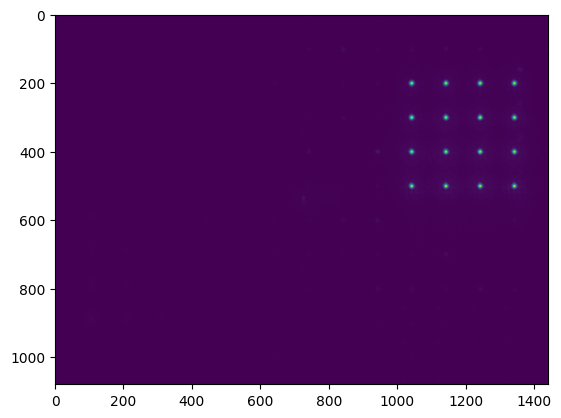

In [645]:
img  = plot_cam(fs,phase = phis[46].numpy())

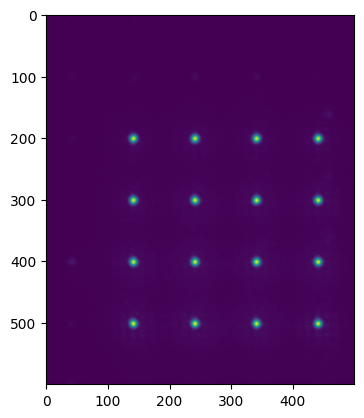

In [646]:
plt.imshow(img[0:600,900:1400])

In [653]:
save_cam(fs,phase = phis[65].numpy(),file_name="spots_iwp_u_27apr_65")

writing phase


writing phase


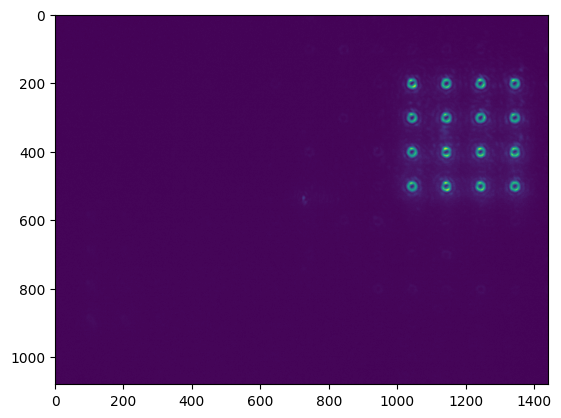

In [641]:
img = plot_cam(fs,phase= phis[46].numpy() + bottle_beam_phase(fs))

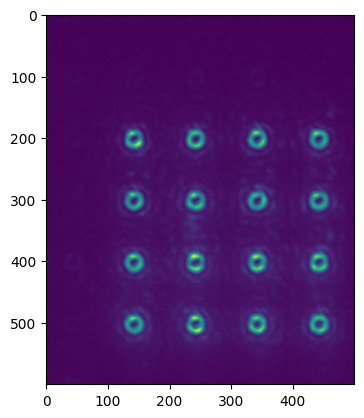

In [643]:
plt.imshow(img[0:600,900:1400])